# Small sequence models on an hourly station series

Next-hour temperature at KHSV (Huntsville) from a 24-hour window of temperature, dewpoint, wind speed, and sea-level pressure. Three forecasts:

1. Persistence: the last hour is the forecast.
2. A temporal CNN with two dilated 1D convolutions.
3. A 1D Transformer with two encoder layers.

One year of one station is a few thousand sequences. That fits a free Colab T4 if the window stays at 24 hours and the batch size stays at 64. The point is a fair baseline, not a forecast product.

Data are routine hourly observations from the Iowa Environmental Mesonet ASOS archive. No account.

**Result.** The Transformer beats persistence by 0.24°F on next-hour temperature (1.28°F against 1.52°F). That gain is the diurnal cycle. It sits on the morning rise and the evening drop, and it vanishes when each hour is measured against its training-set mean (−0.008°F). On dewpoint the same model loses to persistence by 0.20°F. At one station and a one-hour horizon, the last observation plus the daily cycle is the forecast.


In [ ]:
# Colab setup.
%pip install -q torch pandas numpy scikit-learn matplotlib


In [ ]:
import numpy as np
import pandas as pd
import requests
from io import StringIO

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

STATION = "HSV"
YEAR = 2024
WINDOW = 24          # hours of history
HORIZON = 1          # predict this many hours ahead
BATCH = 64
EPOCHS = 20
LR = 1e-3
SEED = 7
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
np.random.seed(SEED)
print("device:", DEVICE)


## Load one year of KHSV

Report type 3 is routine hourly observations. Missing values are marked `M`. A short gap is filled by time interpolation. A gap longer than 3 hours is left missing, and any window that touches it is dropped.


In [ ]:
url = "https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py"
params = {
    "station": STATION,
    "data": ["tmpf", "dwpf", "sknt", "mslp"],
    "year1": YEAR, "month1": 1, "day1": 1,
    "year2": YEAR, "month2": 12, "day2": 31,
    "tz": "Etc/UTC",
    "format": "onlycomma",
    "latlon": "no",
    "elev": "no",
    "missing": "M",
    "trace": "T",
    "direct": "no",
    "report_type": 3,
}
r = requests.get(url, params=params, timeout=120)
r.raise_for_status()
raw = pd.read_csv(StringIO(r.text), na_values=["M"])
raw["valid"] = pd.to_datetime(raw["valid"], utc=True)
raw = raw.set_index("valid").sort_index()

hourly = raw[["tmpf", "dwpf", "sknt", "mslp"]].resample("1h").mean()
gap = hourly.isna().any(axis=1)
# Interpolate only across gaps of 3 hours or less.
hourly = hourly.interpolate(method="time", limit=3)
hourly = hourly.dropna()
print(hourly.shape)
print(hourly.head(3))
print("retained fraction:", len(hourly) / (366 * 24))


## Windows and a time split

Each sample is 24 hours of the four variables. The target is the temperature at the next hour. The last 60 days are the test set, so the split is in time rather than shuffled. Scaling is fit on the training windows only.


In [ ]:
cols = ["tmpf", "dwpf", "sknt", "mslp"]
values = hourly[cols].to_numpy(dtype=np.float32)
times = hourly.index

X, y, t_end = [], [], []
for i in range(WINDOW, len(values) - HORIZON + 1):
    X.append(values[i - WINDOW:i])
    y.append(values[i + HORIZON - 1, 0])  # tmpf is column 0
    t_end.append(times[i + HORIZON - 1])
X = np.stack(X)
y = np.asarray(y, dtype=np.float32)
t_end = pd.DatetimeIndex(t_end)

split = t_end.max() - pd.Timedelta(days=60)
train = t_end < split
test = ~train
print("train", int(train.sum()), "test", int(test.sum()), "split", split)

scaler = StandardScaler()
scaler.fit(X[train].reshape(-1, X.shape[-1]))
def scale(a):
    flat = scaler.transform(a.reshape(-1, a.shape[-1]))
    return flat.reshape(a.shape).astype(np.float32)

X_train, X_test = scale(X[train]), scale(X[test])
y_train, y_test = y[train], y[test]
# Persistence uses the last observed temperature, still in degrees F.
persist = X[test][:, -1, 0]

def loaders():
    tr = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    te = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
    return (
        DataLoader(tr, batch_size=BATCH, shuffle=True),
        DataLoader(te, batch_size=BATCH, shuffle=False),
    )


## Models

The CNN applies two dilated convolutions and then averages the window. The Transformer uses a learned position vector, two encoder layers, and the last token as the forecast. Both heads emit one number, in degrees F. Persistence is the last observed temperature.


In [ ]:
class TemporalCNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_features, 32, kernel_size=3, padding=2, dilation=2),
            nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=3, padding=4, dilation=4),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.head = nn.Linear(32, 1)

    def forward(self, x):
        # x: (batch, time, features) -> (batch, features, time)
        h = self.net(x.transpose(1, 2)).squeeze(-1)
        return self.head(h).squeeze(-1)


class TinyTransformer(nn.Module):
    def __init__(self, n_features, length, d_model=32, nhead=4, layers=2):
        super().__init__()
        self.proj = nn.Linear(n_features, d_model)
        self.pos = nn.Parameter(torch.zeros(1, length, d_model))
        block = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=64,
            batch_first=True, dropout=0.1,
        )
        self.encoder = nn.TransformerEncoder(block, num_layers=layers)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.encoder(self.proj(x) + self.pos)
        return self.head(h[:, -1]).squeeze(-1)


def count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

cnn = TemporalCNN(X.shape[-1]).to(DEVICE)
tfm = TinyTransformer(X.shape[-1], WINDOW).to(DEVICE)
print("CNN parameters", count(cnn), "Transformer parameters", count(tfm))


## Train

Mean squared error against the observed next-hour temperature. The reported test metric is MAE in degrees F.


In [ ]:
def train(model, epochs=EPOCHS):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    tr, _ = loaders()
    history = []
    for epoch in range(epochs):
        total, n = 0.0, 0
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            n += len(xb)
        history.append(total / n)
    return history


def predict(model):
    model.eval()
    _, te = loaders()
    out = []
    with torch.no_grad():
        for xb, _ in te:
            out.append(model(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)


def mae(a, b):
    return float(np.mean(np.abs(a - b)))

cnn_hist = train(cnn)
tfm_hist = train(tfm)
cnn_hat = predict(cnn)
tfm_hat = predict(tfm)

print(f"persistence MAE {mae(persist, y_test):.3f} F")
print(f"CNN         MAE {mae(cnn_hat, y_test):.3f} F")
print(f"Transformer MAE {mae(tfm_hat, y_test):.3f} F")


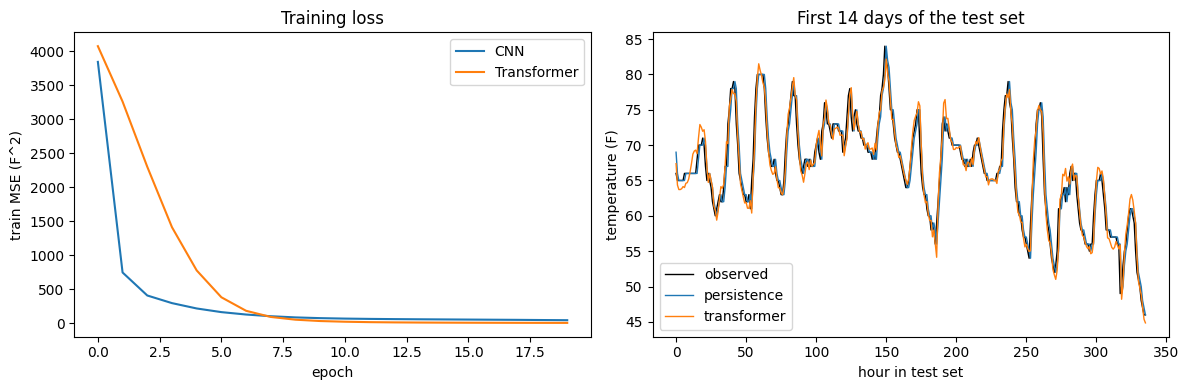

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cnn_hist, label="CNN")
axes[0].plot(tfm_hist, label="Transformer")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("train MSE (F^2)")
axes[0].legend()
axes[0].set_title("Training loss")

show = slice(0, 24 * 14)
axes[1].plot(y_test[show], label="observed", color="k", linewidth=1)
axes[1].plot(persist[show], label="persistence", linewidth=1)
axes[1].plot(tfm_hat[show], label="transformer", linewidth=1)
axes[1].set_xlabel("hour in test set")
axes[1].set_ylabel("temperature (F)")
axes[1].legend()
axes[1].set_title("First 14 days of the test set")
fig.tight_layout()
plt.show()


### First result

The Transformer clears the bar. The CNN does not.

Persistence is 1.52°F MAE. The Transformer is 1.28°F, a gain of 0.24°F. On the test-set plot the Transformer sits on the observations and peels off at the peaks and the sharp drops, where persistence is one hour late. The CNN is 5.19°F. Averaging the window throws away the last observation, which is the useful input for a one-hour forecast.


## Residual by hour of day

If the gain is only on the morning rise and the evening drop, the model has learned the diurnal cycle.


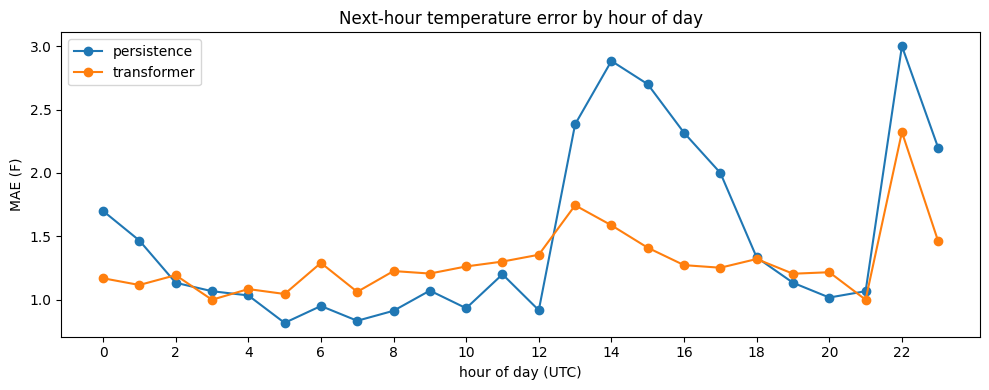

In [1]:
test_times = t_end[test]
hour = test_times.hour
rows = []
for h in range(24):
    m = hour == h
    if m.sum() == 0:
        continue
    rows.append({
        "hour": h,
        "n": int(m.sum()),
        "persist_mae": mae(persist[m], y_test[m]),
        "tfm_mae": mae(tfm_hat[m], y_test[m]),
    })
by_hour = pd.DataFrame(rows)
by_hour["gain"] = by_hour["persist_mae"] - by_hour["tfm_mae"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_hour["hour"], by_hour["persist_mae"], marker="o", label="persistence")
ax.plot(by_hour["hour"], by_hour["tfm_mae"], marker="o", label="transformer")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day (UTC)")
ax.set_ylabel("MAE (F)")
ax.set_title("Next-hour temperature error by hour of day")
ax.legend()
fig.tight_layout()
plt.show()

print(by_hour.round(3).to_string(index=False))
print(
    "afternoon gain (18–23 UTC):",
    f"{by_hour.loc[by_hour.hour.between(18, 23), 'gain'].mean():.3f} F",
    "| overnight gain (0–11 UTC):",
    f"{by_hour.loc[by_hour.hour.between(0, 11), 'gain'].mean():.3f} F",
)


### Hour-of-day residual

The gain is the diurnal cycle. The large improvements, 0.6–1.3°F, sit at 13–17 UTC, which is 08–12 CDT in October: the morning rise, where persistence is always late. A smaller win appears at 22–23 UTC, on the evening drop. Overnight the Transformer is slightly worse than persistence, by about 0.07°F. The printed afternoon gain of 0.20°F is almost entirely those two evening hours.


## Remove the hour of day

Subtract the training-set mean temperature for each hour from the target and from every temperature in the window, then retrain. If the Transformer still beats persistence on the anomalies, it is using the other variables.


In [ ]:
# Training-set mean temperature by hour of the target time. Test hours use this same table.
split = t_end.max() - pd.Timedelta(days=60)
train_mask = np.asarray(t_end < split)
test_mask = ~train_mask
hour_all = np.asarray(t_end.hour)

clim = (
    pd.Series(y[train_mask], index=hour_all[train_mask])
    .groupby(level=0)
    .mean()
    .reindex(range(24))
)
clim = clim.fillna(clim.mean())

# Anomaly the temperature column at every hour of the window, and the target.
X_anom = X.copy()
for i, h in enumerate(hour_all):
    # Window ends at the hour before the target.
    window_hours = [(h - WINDOW + k) % 24 for k in range(WINDOW)]
    X_anom[i, :, 0] = X[i, :, 0] - clim.loc[window_hours].to_numpy()
y_anom = y - clim.loc[hour_all].to_numpy()

scaler_a = StandardScaler()
scaler_a.fit(X_anom[train_mask].reshape(-1, X_anom.shape[-1]))

def scale_a(a):
    flat = scaler_a.transform(a.reshape(-1, a.shape[-1]))
    return flat.reshape(a.shape).astype(np.float32)

Xtr_a, Xte_a = scale_a(X_anom[train_mask]), scale_a(X_anom[test_mask])
ytr_a, yte_a = y_anom[train_mask], y_anom[test_mask]
persist_a = X_anom[test_mask][:, -1, 0]

tfm_a = TinyTransformer(X.shape[-1], WINDOW).to(DEVICE)
opt = torch.optim.Adam(tfm_a.parameters(), lr=LR)
loss_fn = nn.MSELoss()
tr = DataLoader(
    TensorDataset(torch.from_numpy(Xtr_a), torch.from_numpy(ytr_a)),
    batch_size=BATCH, shuffle=True,
)
tfm_a.train()
for epoch in range(EPOCHS):
    for xb, yb in tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        loss_fn(tfm_a(xb), yb).backward()
        opt.step()

tfm_a.eval()
te = DataLoader(
    TensorDataset(torch.from_numpy(Xte_a), torch.from_numpy(yte_a)),
    batch_size=BATCH, shuffle=False,
)
hat_a = []
with torch.no_grad():
    for xb, _ in te:
        hat_a.append(tfm_a(xb.to(DEVICE)).cpu().numpy())
hat_a = np.concatenate(hat_a)

print(f"anomaly persistence MAE {mae(persist_a, yte_a):.3f} F")
print(f"anomaly transformer  MAE {mae(hat_a, yte_a):.3f} F")
print(f"gain {mae(persist_a, yte_a) - mae(hat_a, yte_a):.3f} F")


### Anomaly test

The gain is gone. Persistence is 1.331°F and the Transformer is 1.338°F, a difference of −0.008°F. Dewpoint, wind, and pressure add nothing the last observation does not already carry. The 0.24°F was the daily rise and fall.


## A second target

Dewpoint, with the same windows. Temperature is the easy series.


In [ ]:
# Dewpoint is column 1. Rebuild the target from the same windows.
y_dw = X[:, -1, 1].copy()
# The window ends one hour before the target, so recover the target hour's dewpoint
# from the original hourly series. Column order is tmpf, dwpf, sknt, mslp.
dw = hourly["dwpf"].to_numpy(dtype=np.float32)
# t_end indexes the target hour in the hourly frame.
dw_by_time = hourly["dwpf"]
y_dw = dw_by_time.reindex(t_end).to_numpy(dtype=np.float32)

split = t_end.max() - pd.Timedelta(days=60)
train_mask = np.asarray(t_end < split)
test_mask = ~train_mask

Xtr_dw, Xte_dw = scale(X[train_mask]), scale(X[test_mask])
ytr_dw, yte_dw = y_dw[train_mask], y_dw[test_mask]
persist_dw = X[test_mask][:, -1, 1]

tfm_dw = TinyTransformer(X.shape[-1], WINDOW).to(DEVICE)
opt = torch.optim.Adam(tfm_dw.parameters(), lr=LR)
loss_fn = nn.MSELoss()
tr = DataLoader(
    TensorDataset(torch.from_numpy(Xtr_dw), torch.from_numpy(ytr_dw)),
    batch_size=BATCH, shuffle=True,
)
tfm_dw.train()
for epoch in range(EPOCHS):
    for xb, yb in tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        loss_fn(tfm_dw(xb), yb).backward()
        opt.step()

tfm_dw.eval()
te = DataLoader(
    TensorDataset(torch.from_numpy(Xte_dw), torch.from_numpy(yte_dw)),
    batch_size=BATCH, shuffle=False,
)
hat_dw = []
with torch.no_grad():
    for xb, _ in te:
        hat_dw.append(tfm_dw(xb.to(DEVICE)).cpu().numpy())
hat_dw = np.concatenate(hat_dw)

print(f"dewpoint persistence MAE {mae(persist_dw, yte_dw):.3f} F")
print(f"dewpoint transformer  MAE {mae(hat_dw, yte_dw):.3f} F")
print(f"gain {mae(persist_dw, yte_dw) - mae(hat_dw, yte_dw):.3f} F")


### Dewpoint

Dewpoint is worse. Persistence is 0.97°F and the Transformer is 1.17°F, a loss of 0.20°F. Adding the other variables makes the next-hour dewpoint forecast worse, not better.


## Conclusion

At one station and a one-hour horizon, a small sequence model does not beat the last observation once the diurnal cycle is removed.

- On temperature, the Transformer beats persistence by 0.24°F. The CNN, which averages the window, loses badly.
- That 0.24°F is concentrated on the morning rise and the evening drop. Overnight the model is slightly worse than persistence.
- After subtracting the training-set hourly mean, the gain is −0.008°F. The other variables were not doing work.
- On dewpoint the Transformer loses to persistence by 0.20°F.

The architecture is fine. The target does not contain a one-hour signal beyond persistence and the daily cycle. A longer horizon, or a target that is not a smooth hourly series, is a different problem.

## Citations

Iowa Environmental Mesonet, Iowa State University. ASOS/AWOS observations, station HSV, 2024. https://mesonet.agron.iastate.edu/

Paszke and coauthors, 2019: PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems* 32.

Vaswani and coauthors, 2017: Attention is all you need. *Advances in Neural Information Processing Systems* 30.
